In [17]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter, medfilt, welch, filtfilt

**Loading Data**

In [2]:
# Load the data
magnitude_data = sio.loadmat(r'Zakir_sitting\P01A\P0A1\Amplitude.mat')
phase_data = sio.loadmat(r'Zakir_sitting\P01A\P0A1\Phase.mat')

In [4]:
magnitude = magnitude_data["Data_amplitude"]  # replace 'variable_name' with the correct variable name
phase = phase_data["Data_phase"]

**Moving Average Filter**

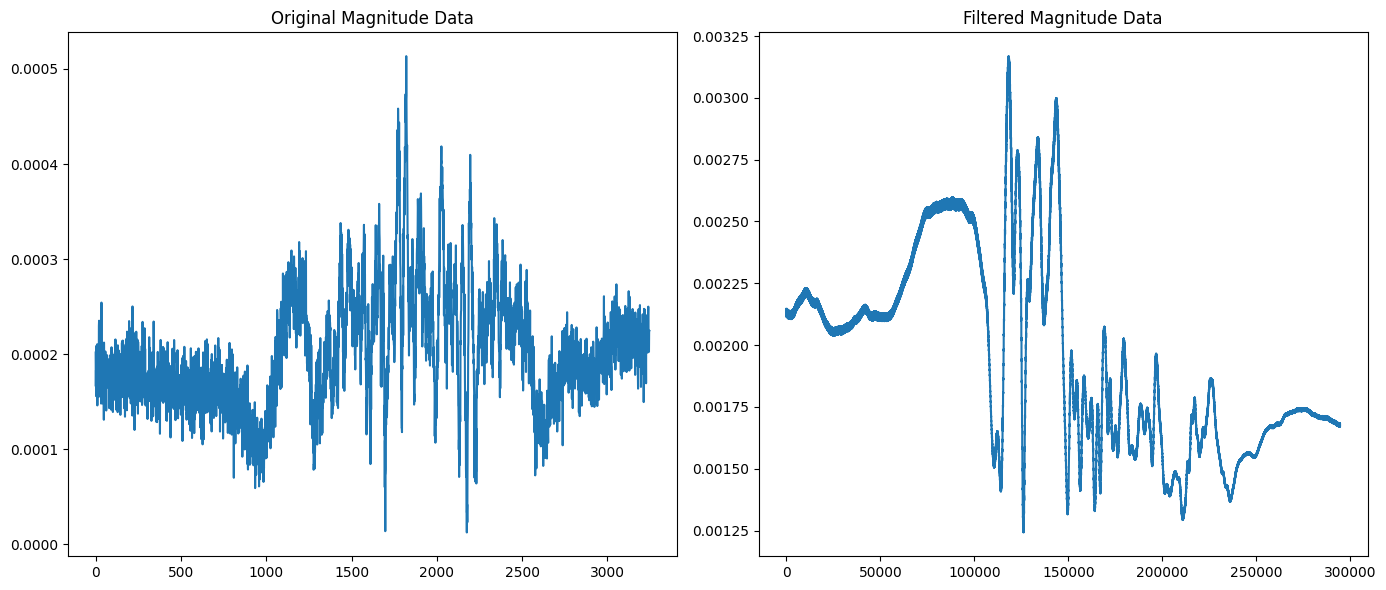

In [14]:
# Apply a moving average filter
window_size = 1000  # Adjust as needed
filtered_magnitude = np.convolve(magnitude.flatten(), np.ones(window_size)/window_size, mode='valid')

# Plot original and filtered data
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(magnitude[:, 90])
plt.title('Original Magnitude Data')

plt.subplot(1, 2, 2)
plt.plot(filtered_magnitude)
plt.title('Filtered Magnitude Data')
plt.tight_layout()
plt.show()


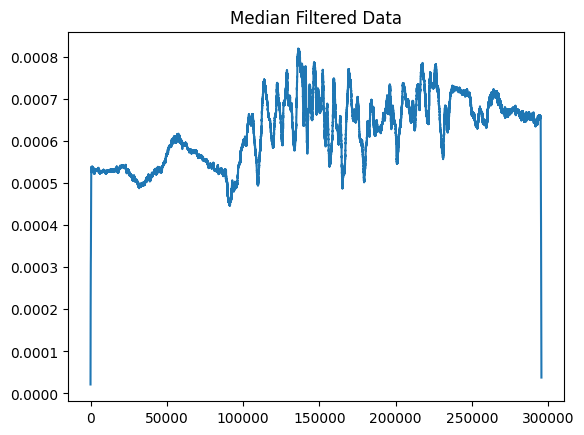

In [21]:
median_filtered = medfilt(magnitude.flatten(), kernel_size=999)

plt.figure()
plt.plot(median_filtered)
plt.title('Median Filtered Data')
plt.show()


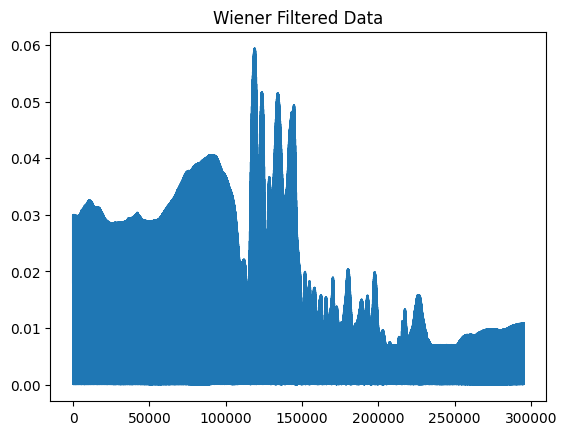

In [23]:
from scipy.signal import wiener

wiener_filtered = wiener(magnitude.flatten())

plt.figure()
plt.plot(wiener_filtered)
plt.title('Wiener Filtered Data')
plt.show()


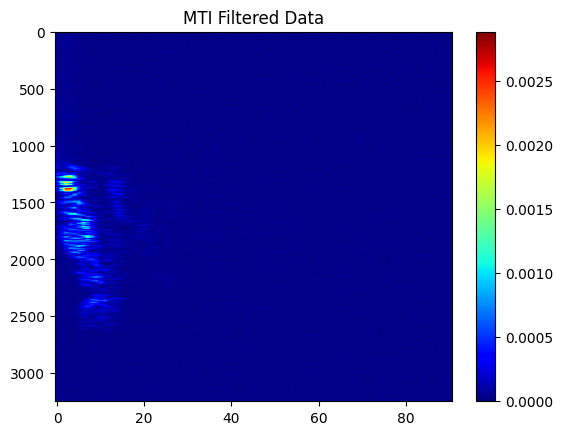

In [24]:
def mti_filter(data, num_previous_scans=1):
    """
    Simple MTI filter.
    data: 2D radar data, where each row is a separate scan and columns represent range bins.
    num_previous_scans: The number of previous scans to subtract from the current scan.
    """
    mti_output = np.zeros_like(data)
    for i in range(num_previous_scans, len(data)):
        mti_output[i] = data[i] - data[i - num_previous_scans]
    return mti_output

# Apply MTI filter
mti_filtered_data = mti_filter(magnitude)

plt.figure()
plt.imshow(np.abs(mti_filtered_data), aspect='auto', cmap='jet')
plt.title('MTI Filtered Data')
plt.colorbar()
plt.show()


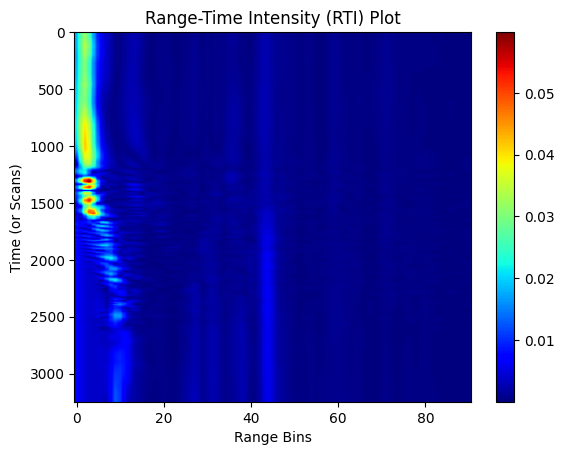

In [25]:
plt.figure()
plt.imshow(np.abs(magnitude), aspect='auto', cmap='jet')
plt.title('Range-Time Intensity (RTI) Plot')
plt.colorbar()
plt.xlabel('Range Bins')
plt.ylabel('Time (or Scans)')
plt.show()
